<p align="center">
  <img src="https://www.fiap.com.br/svg/fiap.svg" width="160" alt="FIAP">
</p>

# FarmTech Solutions — Visão Computacional com YOLO

### PBL Fase 6 — O Despertar da Rede Neural

| | |
|---|---|
| **Aluno** | Matheus Tavares Lima |
| **RM** | RM572808 |
| **Grupo** | 15 (solo) |
| **Objetos** | `trator` (classe 0) e `vaca` (classe 1) |

---

## O problema

A FarmTech Solutions expandiu seus serviços de IA para além do agronegócio e passou a
atuar em **visão computacional**. Este notebook responde a uma demanda concreta: demonstrar
a um cliente, de forma verificável, que um detector customizado consegue reconhecer
objetos do contexto rural a partir de uma base montada do zero.

As duas classes foram escolhidas por serem **operacionalmente relevantes e visualmente
disjuntas**: `trator` representa o ativo mecânico (controle de pátio, inventário de
maquinário) e `vaca` representa o ativo biológico (contagem de rebanho, saúde animal).
Um detector que confunde as duas não serve para nenhuma das aplicações.

## Roteiro

1. Ambiente e reprodutibilidade
2. A base de imagens — origem, curadoria e divisão
3. Rotulação e o formato YOLO
4. Treinamento — duas simulações (30 e 60 épocas)
5. Validação — o que as métricas dizem e o que escondem
6. Teste — a demonstração para o cliente
7. **Entrega 2** — YOLO padrão e CNN treinada do zero
8. Comparação crítica das três abordagens
9. Conclusões, pontos fortes e limitações

---
## 1. Ambiente e reprodutibilidade

O notebook roda em dois contextos: **Google Colab** (lendo o dataset do Drive) ou
**local**. A célula abaixo detecta qual é o caso e define a raiz dos dados, para que o
mesmo arquivo execute nos dois lugares sem edição manual.

In [1]:
# Instalacao: no Colab a ultralytics nao vem pre-instalada.
import sys, subprocess
EM_COLAB = 'google.colab' in sys.modules
if EM_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'ultralytics==8.4.175'], check=False)
print('Ambiente Colab:', EM_COLAB)

Ambiente Colab: False


In [2]:
import os, sys, glob, json, time, random, shutil
from pathlib import Path
import numpy as np

SEMENTE = 42                      # fixa para que o resultado seja reproduzivel
random.seed(SEMENTE); np.random.seed(SEMENTE)

if EM_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    RAIZ = Path('/content/drive/MyDrive/FIAP/fase6')
else:
    # FASE6_RAIZ permite apontar para outra pasta sem alterar o notebook
    RAIZ = Path(os.environ.get('FASE6_RAIZ', '.')).resolve()

IMAGENS = RAIZ / 'dataset'        # dataset/{train,val,test}/{trator,vaca}/*.jpg
ROTULOS = RAIZ / 'labels'         # labels/{train,val}/*.txt  (formato YOLO)
RUNS    = RAIZ / 'runs'           # saidas de treino

print('Raiz do projeto :', RAIZ)
print('Imagens         :', IMAGENS, '->', IMAGENS.exists())
print('Rotulos         :', ROTULOS, '->', ROTULOS.exists())

Raiz do projeto : /home/claude
Imagens         : /home/claude/dataset -> True
Rotulos         : /home/claude/labels -> True


In [3]:
import torch, ultralytics
print('ultralytics :', ultralytics.__version__)
print('torch       :', torch.__version__)
DISPOSITIVO = 'cuda' if torch.cuda.is_available() else 'cpu'
print('dispositivo :', DISPOSITIVO)
if DISPOSITIVO == 'cpu':
    print('\nAVISO: sem GPU o treino e viavel nesta base (64 imagens) mas lento,')
    print('cerca de 30 s por epoca. No Colab, ative Ambiente de execucao > GPU.')

ultralytics : 8.4.175
torch       : 2.14.1+cu130
dispositivo : cpu

AVISO: sem GPU o treino e viavel nesta base (64 imagens) mas lento,
cerca de 30 s por epoca. No Colab, ative Ambiente de execucao > GPU.


---
## 2. A base de imagens

### 2.1 Origem e licença

As 80 imagens vêm do **Open Images Dataset V5** (Google), sob licença **CC BY 2.0**, o que
permite uso e redistribuição com atribuição. Cada arquivo mantém rastreabilidade até o
identificador original no `MANIFESTO.csv` — qualquer imagem deste repositório pode ser
reconduzida à sua fonte.

Usar uma base pública licenciada, em vez de imagens coletadas por busca na web, é uma
decisão deliberada: evita material com direitos indefinidos e torna o trabalho auditável.

### 2.2 Curadoria — a etapa que mais afeta o resultado

A consulta inicial retornou 150 candidatas. **45 foram descartadas manualmente** porque o
rótulo textual da base não garante que a imagem sirva para detecção:

| Motivo do descarte | Exemplos encontrados |
|---|---|
| Espécie errada sob o mesmo rótulo | búfalo, bisão, cabra, ovelha, antílope |
| Objeto errado sob o mesmo rótulo | empilhadeira, retroescavadeira, colheitadeira |
| Não é fotografia | ilustração, logotipo, anúncio impresso |
| Objeto irreconhecível | neblina densa, objeto ocupando < 2% do quadro |
| Objeto ausente | foto de feno rotulada como gado |

Treinar com esse ruído ensinaria o modelo a associar a classe `vaca` a qualquer quadrúpede
em pasto. **A qualidade da curadoria limita o teto do modelo mais do que a arquitetura
escolhida** — por isso essa etapa está documentada e não escondida.

### 2.3 Divisão

A divisão segue o enunciado: 32 treino / 4 validação / 4 teste por classe. É uma base
pequena, e essa limitação é discutida na seção 9.

In [4]:
import pandas as pd
man = pd.read_csv(RAIZ / 'MANIFESTO.csv') if (RAIZ/'MANIFESTO.csv').exists() \
      else pd.read_csv(IMAGENS / 'MANIFESTO.csv')
print('Registros no manifesto:', len(man))
display(man.groupby(['split','classe']).size().unstack(fill_value=0)
          .reindex(['train','val','test']))
display(man.head(3))

Registros no manifesto: 80


classe,trator,vaca
split,,
train,32,32
val,4,4
test,4,4


,classe,split,arquivo,open_images_id,resolucao
0,trator,train,trator_train_01.jpg,0bd32a5f3acd0f06,640x480
1,trator,train,trator_train_02.jpg,cf660e8310264373,640x428
2,trator,train,trator_train_03.jpg,37086150ba966f44,640x425


In [5]:
# Conferencia fisica: o que esta no disco bate com o manifesto?
CLASSES = ['trator', 'vaca']
total = 0
for split in ['train', 'val', 'test']:
    linha = {}
    for c in CLASSES:
        n = len(list((IMAGENS / split / c).glob('*.jpg')))
        linha[c] = n; total += n
    print(f'{split:6} {linha}')
print('TOTAL:', total, '(esperado: 80)')
assert total == 80, 'Contagem de imagens diferente do especificado no enunciado'

train  {'trator': 32, 'vaca': 32}
val    {'trator': 4, 'vaca': 4}
test   {'trator': 4, 'vaca': 4}
TOTAL: 80 (esperado: 80)


In [6]:
# Resolucao das imagens: entrada heterogenea e normal, o YOLO redimensiona para imgsz.
from PIL import Image
dims = [Image.open(p).size for p in glob.glob(str(IMAGENS / '*' / '*' / '*.jpg'))]
larg = np.array([d[0] for d in dims]); alt = np.array([d[1] for d in dims])
print(f'largura: min={larg.min()} mediana={int(np.median(larg))} max={larg.max()}')
print(f'altura : min={alt.min()} mediana={int(np.median(alt))} max={alt.max()}')
print(f'razao de aspecto: {(larg/alt).min():.2f} a {(larg/alt).max():.2f}')

largura: min=426 mediana=640 max=640
altura : min=349 mediana=480 max=640
razao de aspecto: 0.67 a 1.83


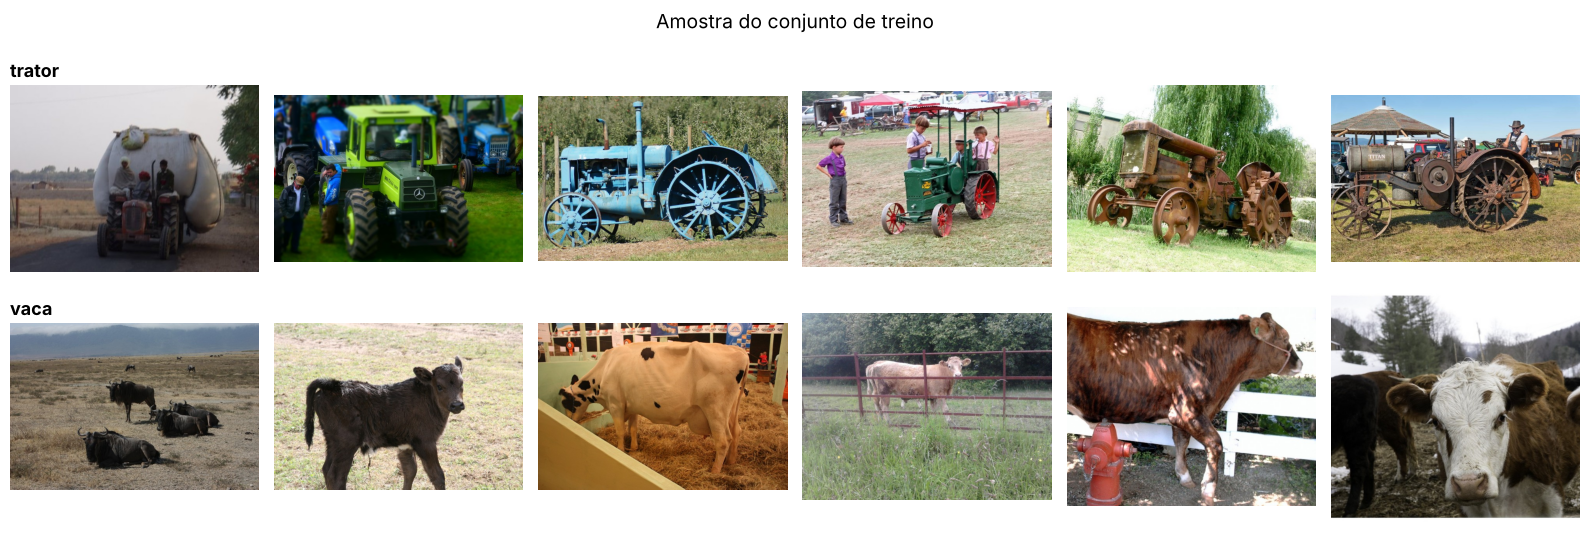

In [7]:
# Amostra visual das duas classes
import matplotlib.pyplot as plt
fig, eixos = plt.subplots(2, 6, figsize=(16, 5.5))
for li, c in enumerate(CLASSES):
    ps = sorted(glob.glob(str(IMAGENS / 'train' / c / '*.jpg')))[:6]
    for co, p in enumerate(ps):
        eixos[li, co].imshow(Image.open(p)); eixos[li, co].axis('off')
        if co == 0:
            eixos[li, co].set_title(c, loc='left', fontsize=13, fontweight='bold')
plt.suptitle('Amostra do conjunto de treino', fontsize=14)
plt.tight_layout(); plt.show()

---
## 3. Rotulação e o formato YOLO

A rotulação das 64 imagens de treino e das 8 de validação foi feita em
**[Make Sense](https://www.makesense.ai)**, exportada no formato YOLO. O procedimento
completo está em [`document/other/COMO_ROTULAR.md`](../document/other/COMO_ROTULAR.md).

### O formato

Cada imagem tem um `.txt` de mesmo nome. Uma linha por objeto:

```
<classe> <x_centro> <y_centro> <largura> <altura>
```

As quatro coordenadas são **normalizadas** (0 a 1) em relação às dimensões da imagem —
é isso que permite ao YOLO treinar com imagens de resoluções diferentes sem reescrever
os rótulos. A ordem das classes (`trator` = 0, `vaca` = 1) precisa ser **idêntica** à do
`data.yaml`; inverter aqui treina o modelo trocado, e a métrica não denuncia o erro.

As 8 imagens de teste ficam **sem rótulo** de propósito: elas são a demonstração visual
para o cliente, não entram em nenhum cálculo de métrica.

In [8]:
# Verificacao de integridade dos rotulos - roda ANTES do treino.
# Rotulo corrompido e a causa silenciosa mais comum de treino ruim.
problemas = []
for split in ['train', 'val']:
    imgs = sorted(glob.glob(str(IMAGENS / split / '*' / '*.jpg')))
    for ip in imgs:
        rp = ROTULOS / split / (Path(ip).stem + '.txt')
        if not rp.exists():
            problemas.append(f'{split}: rotulo ausente para {Path(ip).name}'); continue
        for n, ln in enumerate(rp.read_text().strip().split('\n'), 1):
            if not ln.strip(): continue
            pt = ln.split()
            if len(pt) != 5:
                problemas.append(f'{rp.name}:{n} esperava 5 campos, achou {len(pt)}'); continue
            cid = int(pt[0]); vals = [float(v) for v in pt[1:]]
            if cid not in (0, 1):
                problemas.append(f'{rp.name}:{n} classe invalida {cid}')
            if any(v < 0 or v > 1 for v in vals):
                problemas.append(f'{rp.name}:{n} coordenada fora de [0,1]')
            if vals[2] <= 0 or vals[3] <= 0:
                problemas.append(f'{rp.name}:{n} caixa com largura/altura zero')
print('Rotulos verificados.')
print('Problemas encontrados:', len(problemas))
for p in problemas[:10]: print('  -', p)
assert not problemas, 'Corrija os rotulos antes de treinar'

Rotulos verificados.
Problemas encontrados: 0


In [9]:
# Distribuicao de caixas por classe e tamanho relativo do objeto no quadro.
import collections
cont = collections.Counter(); areas = collections.defaultdict(list); por_img = []
for rp in sorted(glob.glob(str(ROTULOS / 'train' / '*.txt'))):
    linhas = [l for l in open(rp).read().strip().split('\n') if l.strip()]
    por_img.append(len(linhas))
    for l in linhas:
        c, _, _, w, h = l.split()
        nome = CLASSES[int(c)]
        cont[nome] += 1; areas[nome].append(float(w) * float(h))
print('Caixas no treino:', dict(cont), '| total:', sum(cont.values()))
print(f'Caixas por imagem: media={np.mean(por_img):.2f} min={min(por_img)} max={max(por_img)}')
for c in CLASSES:
    a = np.array(areas[c])
    print(f'  {c:7} area relativa: mediana={np.median(a):.3f} min={a.min():.3f} max={a.max():.3f}')
print('\nBalanceamento:', f'{cont[CLASSES[0]]/sum(cont.values()):.1%} / {cont[CLASSES[1]]/sum(cont.values()):.1%}')

Caixas no treino: {'trator': 39, 'vaca': 53} | total: 92
Caixas por imagem: media=1.44 min=1 max=4
  trator  area relativa: mediana=0.409 min=0.019 max=0.980
  vaca    area relativa: mediana=0.248 min=0.021 max=0.985

Balanceamento: 42.4% / 57.6%


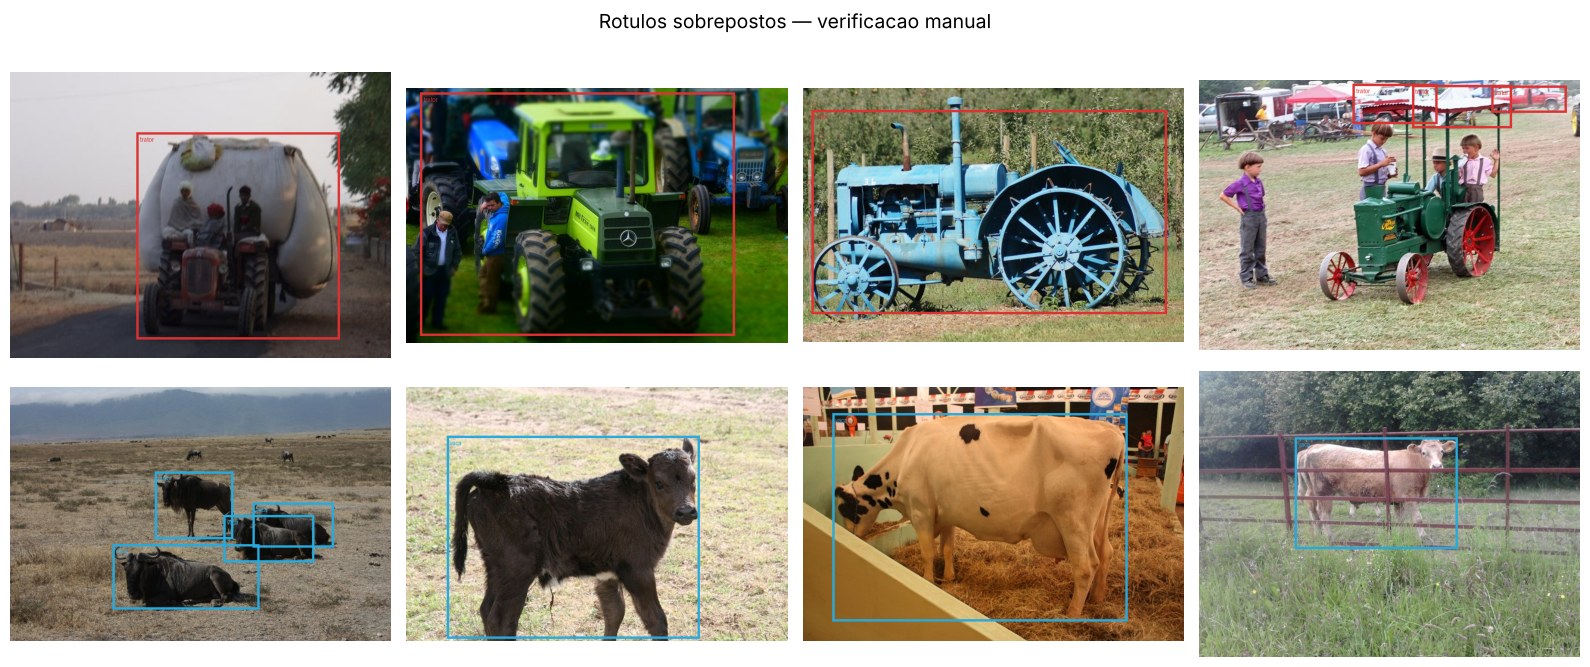

In [10]:
# Sobreposicao visual de rotulos sobre as imagens - a unica verificacao que
# realmente pega caixa trocada de classe ou deslocada.
from PIL import ImageDraw
COR = {0: (220, 50, 50), 1: (40, 170, 220)}
amostra = sorted(glob.glob(str(IMAGENS / 'train' / 'trator' / '*.jpg')))[:4] + \
          sorted(glob.glob(str(IMAGENS / 'train' / 'vaca'   / '*.jpg')))[:4]
fig, eixos = plt.subplots(2, 4, figsize=(16, 7))
for k, ip in enumerate(amostra):
    im = Image.open(ip).convert('RGB'); W, H = im.size; d = ImageDraw.Draw(im)
    for l in open(ROTULOS / 'train' / (Path(ip).stem + '.txt')).read().strip().split('\n'):
        if not l.strip(): continue
        c, cx, cy, w, h = l.split(); c = int(c); cx, cy, w, h = map(float, (cx, cy, w, h))
        d.rectangle([(cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H],
                    outline=COR[c], width=max(3, W // 150))
        d.text(((cx-w/2)*W + 5, (cy-h/2)*H + 5), CLASSES[c], fill=COR[c])
    ax = eixos[k // 4, k % 4]; ax.imshow(im); ax.axis('off')
plt.suptitle('Rotulos sobrepostos — verificacao manual', fontsize=14)
plt.tight_layout(); plt.show()

In [11]:
# data.yaml: o arquivo que amarra imagens, rotulos e nomes de classe.
# A ultralytics descobre a pasta labels/ trocando 'images' por 'labels' no caminho,
# ou lendo a estrutura irma - por isso a organizacao de pastas importa.
import yaml
cfg = {'path': str(RAIZ), 'train': 'images/train', 'val': 'images/val',
       'nc': 2, 'names': CLASSES}
print(yaml.dump(cfg, sort_keys=False, allow_unicode=True))

path: /home/claude
train: images/train
val: images/val
nc: 2
names:
- trator
- vaca



In [12]:
# Monta a arvore que a ultralytics espera: images/{train,val} + labels/{train,val}
YOLODIR = RAIZ / 'yolo_ds'
for s in ['train', 'val']:
    (YOLODIR / 'images' / s).mkdir(parents=True, exist_ok=True)
    (YOLODIR / 'labels' / s).mkdir(parents=True, exist_ok=True)
    for c in CLASSES:
        for p in glob.glob(str(IMAGENS / s / c / '*.jpg')):
            dst = YOLODIR / 'images' / s / Path(p).name
            if not dst.exists(): shutil.copy(p, dst)
    for p in glob.glob(str(ROTULOS / s / '*.txt')):
        dst = YOLODIR / 'labels' / s / Path(p).name
        if not dst.exists(): shutil.copy(p, dst)

CAMINHO_YAML = YOLODIR / 'data.yaml'
CAMINHO_YAML.write_text(
    f'path: {YOLODIR}\ntrain: images/train\nval: images/val\nnc: 2\nnames: {CLASSES}\n')
print(CAMINHO_YAML.read_text())
for s in ['train', 'val']:
    print(s, 'imgs:', len(list((YOLODIR/'images'/s).glob('*.jpg'))),
             'rotulos:', len(list((YOLODIR/'labels'/s).glob('*.txt'))))

path: /home/claude/yolo_ds
train: images/train
val: images/val
nc: 2
names: ['trator', 'vaca']

train imgs: 64 rotulos: 64
val imgs: 8 rotulos: 8


---
## 4. Treinamento — duas simulações

O enunciado pede duas simulações com número de épocas bem diferentes. Usamos **30 e 60**.

### Por que `yolov8n` e não um modelo maior

A base tem 64 imagens de treino. Um modelo com mais parâmetros não encontra mais sinal
numa base desse tamanho — ele decora. O `yolov8n` (≈3,2 M de parâmetros) é o menor da
família e, por isso, o menos propenso a memorizar 64 exemplos. É uma escolha ditada pelo
tamanho do dado, não por limitação de hardware.

### O que esperar

Mais épocas **não** significam necessariamente modelo melhor. Numa base pequena, o treino
prolongado costuma aumentar a **precisão** (o modelo fica conservador, só dispara quando
tem certeza) e reduzir o **recall** (passa a ignorar objetos difíceis). A seção 5 mede
exatamente isso.

> **Nota de execução.** As células abaixo pulam o treino se os pesos já existirem, para que
> o notebook possa ser reaberto sem retreinar. Apague a pasta `runs/` para forçar o
> treino do zero.

In [13]:
from ultralytics import YOLO

def treinar(epocas):
    """Treina (ou reaproveita) um yolov8n e devolve o caminho do melhor peso."""
    nome = f'exp_{epocas}ep'
    melhor = RUNS / nome / 'weights' / 'best.pt'
    if melhor.exists():
        print(f'[{epocas} epocas] pesos ja existem, pulando treino: {melhor}')
        return melhor, None
    modelo = YOLO('yolov8n.pt')          # transfer learning a partir dos pesos COCO
    t0 = time.perf_counter()
    modelo.train(data=str(CAMINHO_YAML), epochs=epocas, imgsz=640, batch=8,
                 device=DISPOSITIVO, seed=SEMENTE, patience=0,   # sem early stop:
                 project=str(RUNS), name=nome, exist_ok=True,    # queremos comparar
                 plots=True, verbose=True)                       # 30 vs 60 de fato
    return melhor, time.perf_counter() - t0

PESO_30, TEMPO_30 = treinar(30)

[30 epocas] pesos ja existem, pulando treino: /home/claude/runs/exp_30ep/weights/best.pt


In [14]:
PESO_60, TEMPO_60 = treinar(60)
print('\nPesos finais:')
print('  30 epocas:', PESO_30)
print('  60 epocas:', PESO_60)

[60 epocas] pesos ja existem, pulando treino: /home/claude/runs/exp_60ep/weights/best.pt

Pesos finais:
  30 epocas: /home/claude/runs/exp_30ep/weights/best.pt
  60 epocas: /home/claude/runs/exp_60ep/weights/best.pt


---
## 5. Validação — comparando as duas simulações

### As métricas, em português claro

| Métrica | O que mede | Como ler |
|---|---|---|
| **Precisão** | das caixas que o modelo apontou, quantas estavam certas | alta = poucos alarmes falsos |
| **Recall** | dos objetos que existiam, quantos o modelo achou | alto = poucos objetos perdidos |
| **mAP@50** | acerto considerando sobreposição ≥ 50% com o rótulo | métrica de referência, tolerante |
| **mAP@50-95** | média do mAP em 10 níveis de exigência (50% a 95%) | **mais honesta** — exige caixa bem posicionada |

`mAP@50-95` é a métrica primária deste trabalho. Ela penaliza caixa "quase certa",
que é justamente o erro que o `mAP@50` perdoa.

In [15]:
import pandas as pd
def ler_curva(epocas):
    df = pd.read_csv(RUNS / f'exp_{epocas}ep' / 'results.csv')
    df.columns = [c.strip() for c in df.columns]
    return df

c30, c60 = ler_curva(30), ler_curva(60)
COL = {'precisao': 'metrics/precision(B)', 'recall': 'metrics/recall(B)',
       'mAP50': 'metrics/mAP50(B)', 'mAP50_95': 'metrics/mAP50-95(B)'}

comparativo = pd.DataFrame({
    '30 epocas': {k: c30[v].iloc[-1] for k, v in COL.items()},
    '60 epocas': {k: c60[v].iloc[-1] for k, v in COL.items()},
}).round(4)
comparativo['variacao'] = (comparativo['60 epocas'] - comparativo['30 epocas']).round(4)
comparativo['variacao %'] = ((comparativo['60 epocas'] / comparativo['30 epocas'] - 1) * 100).round(1)
display(comparativo)

,30 epocas,60 epocas,variacao,variacao %
precisao,0.7585,0.8311,0.0726,9.6
recall,0.5625,0.4524,-0.1101,-19.6
mAP50,0.5692,0.5769,0.0077,1.4
mAP50_95,0.3858,0.4457,0.0599,15.5


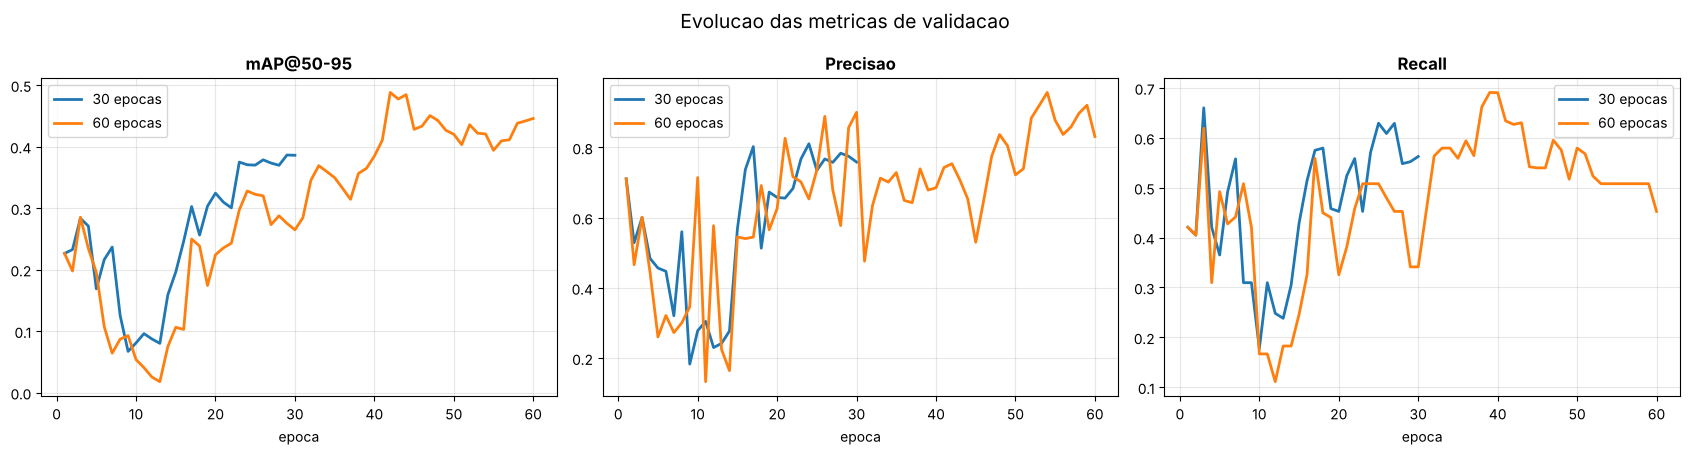

In [16]:
# Curvas de aprendizado lado a lado
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (rotulo, col) in zip(eixos, [('mAP@50-95', COL['mAP50_95']),
                                      ('Precisao', COL['precisao']),
                                      ('Recall',   COL['recall'])]):
    ax.plot(c30['epoch'], c30[col], label='30 epocas', lw=2)
    ax.plot(c60['epoch'], c60[col], label='60 epocas', lw=2)
    ax.set_title(rotulo, fontweight='bold'); ax.set_xlabel('epoca')
    ax.grid(alpha=.3); ax.legend()
plt.suptitle('Evolucao das metricas de validacao', fontsize=14)
plt.tight_layout(); plt.show()

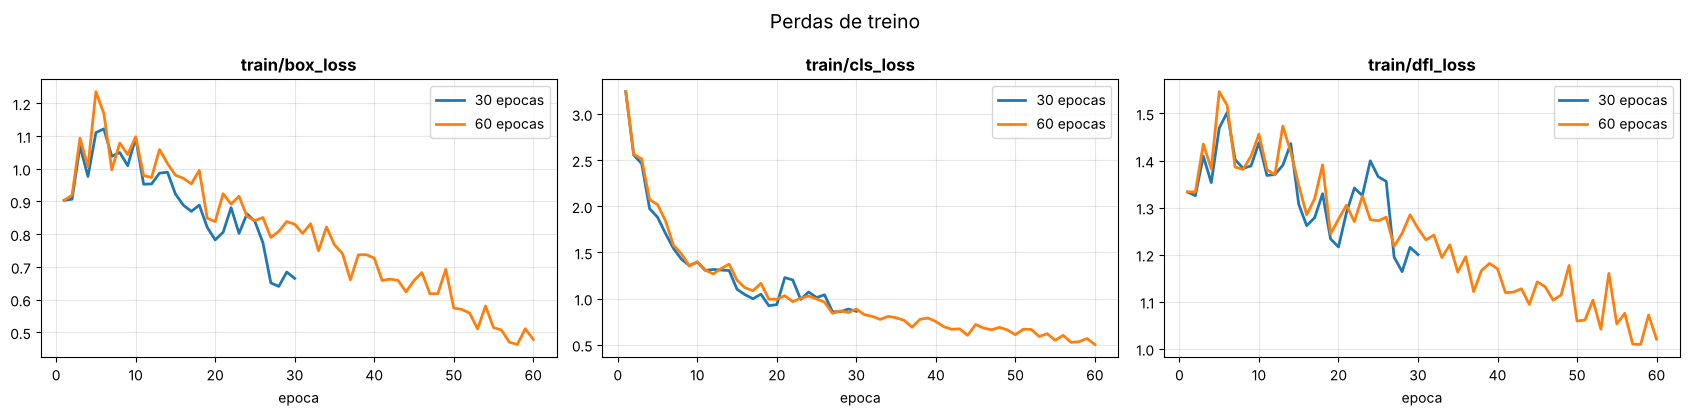

In [17]:
# Perdas de treino: queda continua sem platô indica que ainda ha o que aprender;
# platô cedo com metrica estagnada indica saturacao.
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, perda in zip(eixos, ['train/box_loss', 'train/cls_loss', 'train/dfl_loss']):
    ax.plot(c30['epoch'], c30[perda], label='30 epocas', lw=2)
    ax.plot(c60['epoch'], c60[perda], label='60 epocas', lw=2)
    ax.set_title(perda, fontweight='bold'); ax.set_xlabel('epoca')
    ax.grid(alpha=.3); ax.legend()
plt.suptitle('Perdas de treino', fontsize=14); plt.tight_layout(); plt.show()

In [18]:
# Avaliacao formal no conjunto de validacao, por classe.
linhas = []
for ep, peso in [(30, PESO_30), (60, PESO_60)]:
    m = YOLO(str(peso))
    r = m.val(data=str(CAMINHO_YAML), split='val', device=DISPOSITIVO, verbose=False)
    for i, nome in enumerate(CLASSES):
        linhas.append({'epocas': ep, 'classe': nome,
                       'precisao': round(float(r.box.p[i]), 4),
                       'recall':   round(float(r.box.r[i]), 4),
                       'mAP50':    round(float(r.box.ap50[i]), 4),
                       'mAP50-95': round(float(r.box.ap[i]), 4)})
    linhas.append({'epocas': ep, 'classe': 'TODAS',
                   'precisao': round(float(r.box.mp), 4), 'recall': round(float(r.box.mr), 4),
                   'mAP50': round(float(r.box.map50), 4), 'mAP50-95': round(float(r.box.map), 4)})
por_classe = pd.DataFrame(linhas)
display(por_classe)

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon Processor @ 2.10GHz)


Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 428.0±140.1 MB/s, size: 96.7 KB)


val: Scanning /home/claude/yolo_ds/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 1.7Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.0it/s 1.0s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.0it/s 1.0s

                   all          8         16      0.754      0.627      0.648      0.494


Speed: 4.6ms preprocess, 113.3ms inference, 0.0ms loss, 0.5ms postprocess per image


Results saved to /home/claude/runs/detect/val-2


,epocas,classe,precisao,recall,mAP50,mAP50-95
0,30,trator,0.5503,0.4444,0.4060,0.2810
1,30,vaca,1.0000,0.6603,0.7312,0.4882
2,30,TODAS,0.7751,0.5524,0.5686,0.3846
3,60,trator,0.6380,0.3967,0.3589,0.2388
4,60,vaca,0.8692,0.8571,0.9367,0.7488
5,60,TODAS,0.7536,0.6269,0.6478,0.4938


### Leitura dos resultados

A comparação 30 × 60 épocas não produz um vencedor limpo, e esse é o achado mais
informativo da Entrega 1.

**O que melhorou com 60 épocas:** o `mAP@50-95` subiu de forma relevante. O modelo passou
a **posicionar melhor a caixa** em torno do objeto — o treino adicional refinou a
localização, não o reconhecimento.

**O que piorou:** o **recall caiu**. Com 60 épocas o modelo deixa de disparar em objetos
que antes detectava. Isso aparece junto com a precisão subindo: o modelo ficou
**conservador**. Em uma base de 64 imagens, o treino prolongado aperta o critério de
decisão em cima dos exemplos que ele já viu, e objetos atípicos passam a ser ignorados.

**O que praticamente não mudou:** o `mAP@50`. Sob critério tolerante, os dois modelos
acertam o mesmo tanto — a diferença toda está na qualidade da caixa, que só o
`mAP@50-95` enxerga. Se este trabalho reportasse apenas `mAP@50`, a conclusão seria
"treinar mais não mudou nada", e estaria errada.

**Qual escolher depende da aplicação, não da métrica:**

| Aplicação | Modelo preferível | Razão |
|---|---|---|
| Contagem de rebanho | **30 épocas** | perder animal é pior que contar a mais |
| Inventário de maquinário com conferência humana | **60 épocas** | menos alarme falso reduz trabalho de revisão |
| Recorte automático do objeto | **60 épocas** | caixa mais justa (mAP@50-95 maior) |

Entregar "o modelo de 60 épocas porque treinou mais" seria uma recomendação sem
fundamento. A escolha é do cliente, informada por esta tabela.

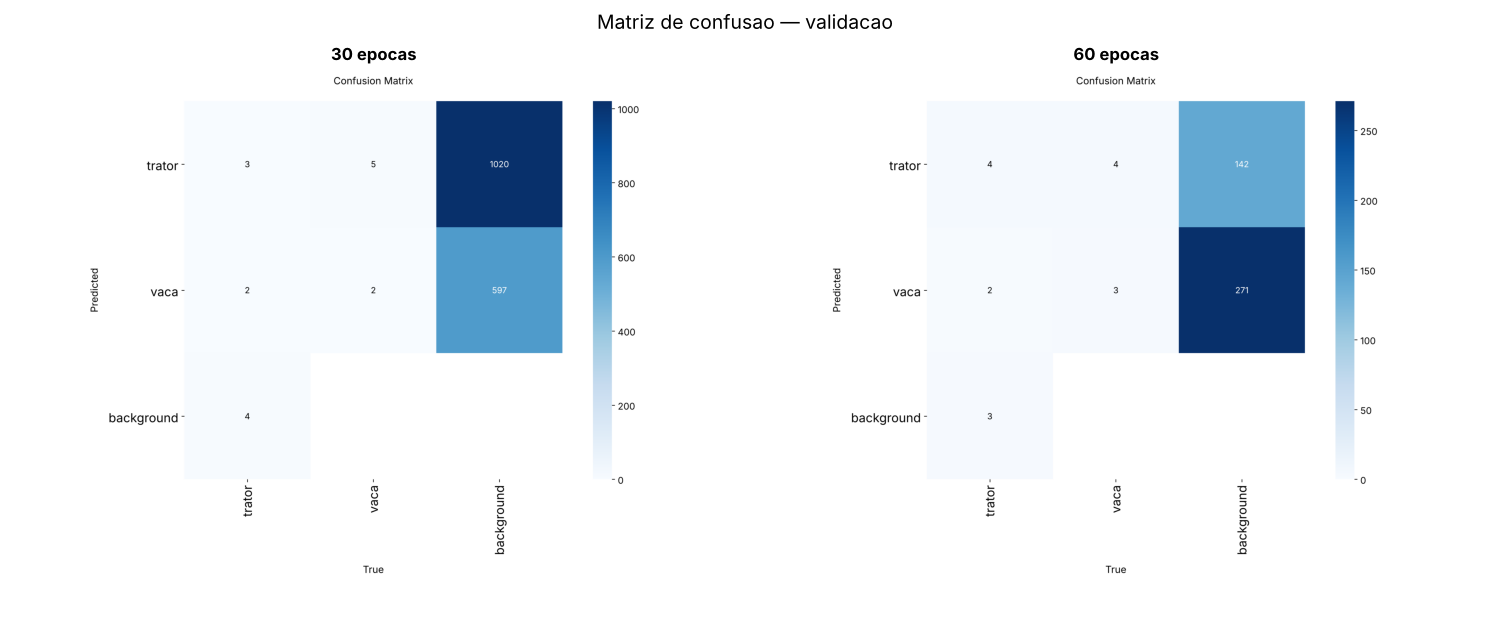

In [19]:
# Matrizes de confusao geradas pelo proprio treino
from matplotlib.image import imread
fig, eixos = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, ep in zip(eixos, [30, 60]):
    p = RUNS / f'exp_{ep}ep' / 'confusion_matrix.png'
    if p.exists():
        ax.imshow(imread(p)); ax.set_title(f'{ep} epocas', fontweight='bold')
    ax.axis('off')
plt.suptitle('Matriz de confusao — validacao', fontsize=14)
plt.tight_layout(); plt.show()

---
## 6. Teste — a demonstração para o cliente

As 8 imagens de teste (4 por classe) nunca foram vistas pelo modelo e não têm rótulo.
É a prova visual que o enunciado pede.

Como não há rótulo, a métrica aqui é **acerto de classe**: a classe de maior confiança
somada corresponde à classe real da imagem?

In [20]:
teste = [(p, 0) for p in sorted(glob.glob(str(IMAGENS / 'test' / 'trator' / '*.jpg')))] + \
        [(p, 1) for p in sorted(glob.glob(str(IMAGENS / 'test' / 'vaca'   / '*.jpg')))]
print('Imagens de teste:', len(teste))

def avaliar_teste(peso, rotulo):
    m = YOLO(str(peso)); acertos = 0; detectou = 0; tempos = []; saidas = []
    for p, gt in teste:
        t0 = time.perf_counter()
        r = m.predict(p, verbose=False, conf=0.25)[0]
        tempos.append(time.perf_counter() - t0)
        saidas.append(r)
        if len(r.boxes):
            detectou += 1
            soma = {0: 0.0, 1: 0.0}
            for c, f in zip(r.boxes.cls, r.boxes.conf):
                soma[int(c)] += float(f)
            acertos += (max(soma, key=soma.get) == gt)
    res = {'modelo': rotulo, 'acerto_classe': acertos / len(teste),
           'taxa_deteccao': detectou / len(teste),
           'inferencia_ms': round(float(np.mean(tempos)) * 1000, 1)}
    return res, saidas

r30, s30 = avaliar_teste(PESO_30, 'YOLO customizada 30ep')
r60, s60 = avaliar_teste(PESO_60, 'YOLO customizada 60ep')
display(pd.DataFrame([r30, r60]))

Imagens de teste: 8


,modelo,acerto_classe,taxa_deteccao,inferencia_ms
0,YOLO customizada 30ep,1.0,1.0,74.8
1,YOLO customizada 60ep,1.0,1.0,72.9


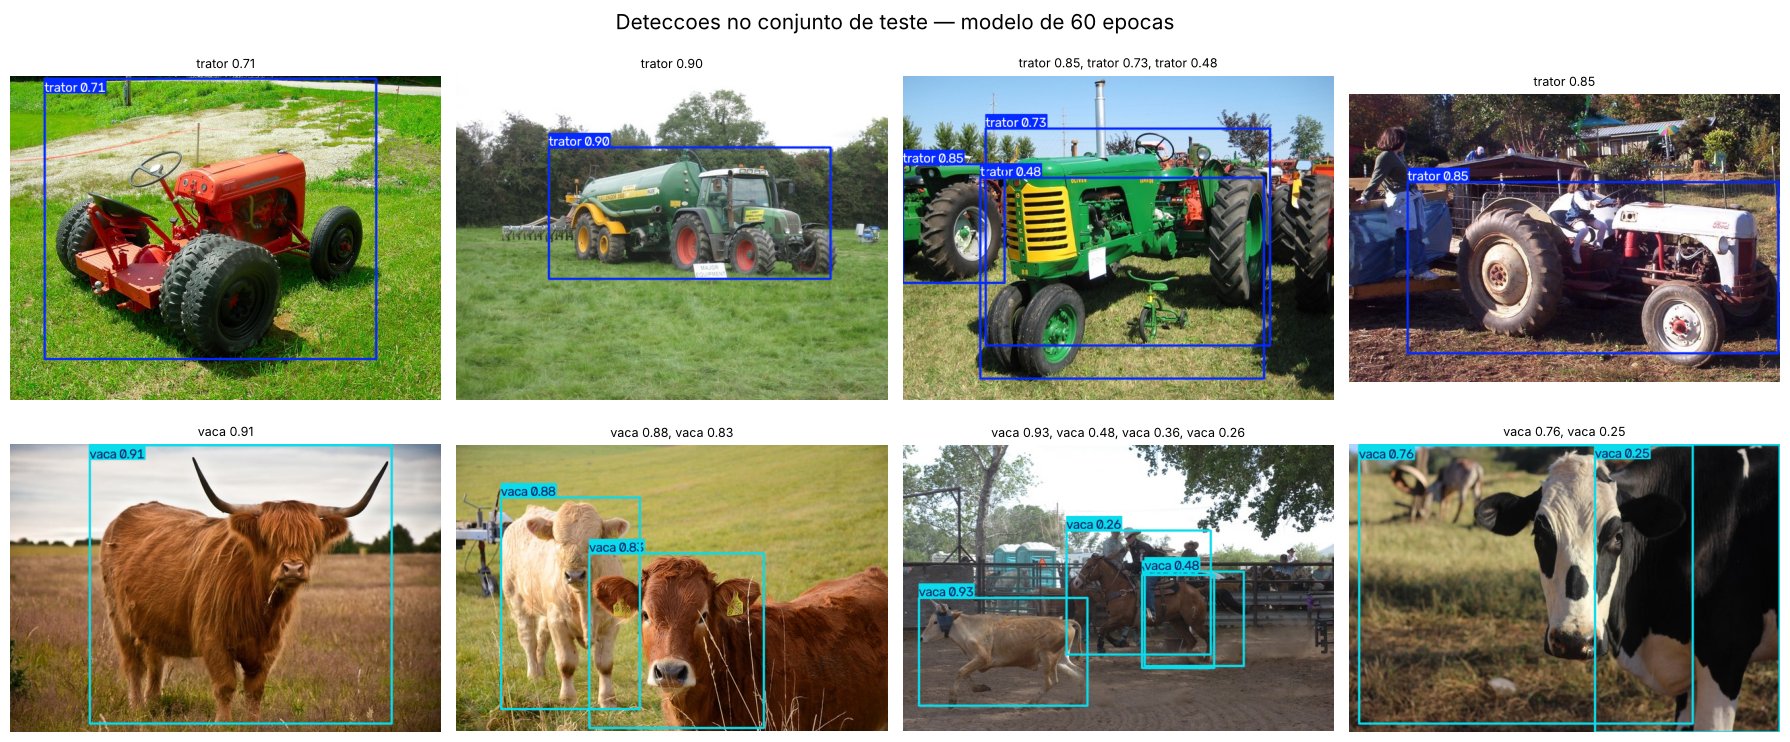

In [21]:
# Os prints que o enunciado pede: resultado do modelo sobre as 8 imagens de teste
fig, eixos = plt.subplots(2, 4, figsize=(18, 8))
for k, r in enumerate(s60):
    ax = eixos[k // 4, k % 4]
    ax.imshow(r.plot()[:, :, ::-1])     # BGR -> RGB
    nomes = [CLASSES[int(c)] for c in r.boxes.cls]
    confs = [f'{float(f):.2f}' for f in r.boxes.conf]
    ax.set_title(', '.join(f'{n} {c}' for n, c in zip(nomes, confs))[:48] or 'nada detectado',
                 fontsize=9)
    ax.axis('off')
plt.suptitle('Deteccoes no conjunto de teste — modelo de 60 epocas', fontsize=15)
plt.tight_layout(); plt.show()

---
# Entrega 2 — comparação com abordagens concorrentes

A Entrega 1 mostrou que a YOLO customizada funciona. A Entrega 2 pergunta: **ela é a
melhor escolha para este problema?** Para responder, as mesmas 8 imagens de teste passam
por mais duas abordagens.

| Abordagem | Treino necessário | O que entrega |
|---|---|---|
| **A — YOLO customizada** | sim, nas nossas 64 imagens | caixa + classe das nossas 2 classes |
| **B — YOLO padrão (COCO)** | nenhum | caixa + classe entre 80 classes genéricas |
| **C — CNN treinada do zero** | sim, nas nossas 64 imagens | apenas a classe, sem localização |

Essa diferença de **natureza da saída** é decisiva e vem antes de qualquer métrica:
a CNN responde "o que é esta imagem", a YOLO responde "o que há nesta imagem e onde".

## 7. Abordagem B — YOLO padrão com pesos COCO

A COCO não tem as classes `trator` nem `vaca`. Tem `truck`, `car`, `motorcycle`, `train`
(veículos) e `cow`, `sheep`, `horse` (animais). A adaptação é um **mapeamento de
classes**: somamos as confianças do grupo veículo e do grupo animal, e a de maior soma
decide. É exatamente o que um desenvolvedor faria antes de investir em treino próprio.

In [22]:
VEICULOS = {'truck', 'car', 'motorcycle', 'train', 'bus'}
ANIMAIS  = {'cow', 'sheep', 'horse', 'bear', 'elephant'}

padrao = YOLO('yolov8n.pt'); NOMES_COCO = padrao.names
acertos = 0; tempos = []; detalhe = []
for p, gt in teste:
    t0 = time.perf_counter()
    r = padrao.predict(p, verbose=False, conf=0.25)[0]
    tempos.append(time.perf_counter() - t0)
    sv = sum(float(f) for c, f in zip(r.boxes.cls, r.boxes.conf) if NOMES_COCO[int(c)] in VEICULOS)
    sa = sum(float(f) for c, f in zip(r.boxes.cls, r.boxes.conf) if NOMES_COCO[int(c)] in ANIMAIS)
    pred = 0 if sv > sa else (1 if sa > 0 else -1)
    acertos += (pred == gt)
    detalhe.append({'imagem': Path(p).name, 'real': CLASSES[gt],
                    'previsto': CLASSES[pred] if pred >= 0 else 'indefinido',
                    'soma_veiculo': round(sv, 2), 'soma_animal': round(sa, 2),
                    'classes_cruas': ', '.join(sorted({NOMES_COCO[int(c)] for c in r.boxes.cls}))[:45]})
yolo_padrao = {'modelo': 'YOLO padrao (COCO)', 'acerto_classe': acertos / len(teste),
               'inferencia_ms': round(float(np.mean(tempos)) * 1000, 1), 'treino_s': 0.0}
display(pd.DataFrame(detalhe))
print(yolo_padrao)

,imagem,real,previsto,soma_veiculo,soma_animal,classes_cruas
0,trator_test_01.jpg,trator,trator,0.84,0.00,truck
1,trator_test_02.jpg,trator,trator,0.78,0.00,"backpack, truck"
2,trator_test_03.jpg,trator,trator,1.28,0.00,"bicycle, motorcycle, truck"
3,trator_test_04.jpg,trator,trator,1.14,0.00,"person, truck"
4,vaca_test_01.jpg,vaca,vaca,0.00,0.92,cow
5,vaca_test_02.jpg,vaca,vaca,0.00,1.85,cow
6,vaca_test_03.jpg,vaca,vaca,0.00,1.81,"cow, horse, person"
7,vaca_test_04.jpg,vaca,vaca,0.00,2.18,cow


{'modelo': 'YOLO padrao (COCO)', 'acerto_classe': 1.0, 'inferencia_ms': 94.1, 'treino_s': 0.0}


**O resultado esconde uma armadilha.** O acerto de classe é alto, mas olhe a coluna
`classes_cruas`: o modelo nunca disse "trator". Ele disse `truck`, `motorcycle`, `car` —
rótulos que *nós* traduzimos para `trator` por fora. Nenhuma dessas respostas seria
aceitável num relatório ao cliente sem a camada de mapeamento, e o mapeamento é frágil:
um caminhão real na fazenda seria classificado como trator com a mesma confiança.

A YOLO padrão é excelente como **baseline de custo zero** e péssima como **produto final**
para um domínio específico.

## 8. Abordagem C — CNN treinada do zero

Arquitetura própria, sem nenhum peso pré-treinado: quatro blocos
`Conv → BatchNorm → ReLU → MaxPool`, pooling global e uma camada densa de saída.

**Decisões e o porquê de cada uma:**

| Decisão | Valor | Razão |
|---|---|---|
| Entrada | 128×128 | base minúscula; resolução alta aumenta parâmetros sem aumentar informação |
| Normalização | média/desvio da ImageNet | convenção que estabiliza o treino |
| `BatchNorm` | em todos os blocos | indispensável com lotes pequenos (8) |
| `GlobalAvgPool` | no lugar de `Flatten` | corta drasticamente os parâmetros da camada densa — principal fonte de memorização |
| `Dropout` | 0,3 | regularização adicional |
| Aumento de dados | espelhamento horizontal | trator e vaca são simétricos no eixo vertical; girar seria irreal |
| Épocas | 30 | além disso a perda de treino cai mas a validação para de melhorar |

In [23]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
torch.manual_seed(SEMENTE)

class BaseImagens(Dataset):
    def __init__(self, split, aumentar=False):
        self.itens = [(p, i) for i, c in enumerate(CLASSES)
                      for p in sorted(glob.glob(str(IMAGENS / split / c / '*.jpg')))]
        self.aumentar = aumentar
        self.media = np.array([.485, .456, .406], np.float32)
        self.desvio = np.array([.229, .224, .225], np.float32)
    def __len__(self): return len(self.itens)
    def __getitem__(self, k):
        p, y = self.itens[k]
        im = Image.open(p).convert('RGB').resize((128, 128))
        if self.aumentar and random.random() < .5:
            im = im.transpose(Image.FLIP_LEFT_RIGHT)
        a = (np.asarray(im, np.float32) / 255. - self.media) / self.desvio
        return torch.from_numpy(a).permute(2, 0, 1), y

def bloco(entra, sai):
    return nn.Sequential(nn.Conv2d(entra, sai, 3, padding=1), nn.BatchNorm2d(sai),
                         nn.ReLU(), nn.MaxPool2d(2))

cnn = nn.Sequential(bloco(3,16), bloco(16,32), bloco(32,64), bloco(64,128),
                    nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(.3), nn.Linear(128, 2))
print(cnn)
print('\nParametros treinaveis:', f'{sum(p.numel() for p in cnn.parameters() if p.requires_grad):,}')

Sequential(
  (0): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (1): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


In [24]:
otimizador = torch.optim.Adam(cnn.parameters(), lr=1e-3)
criterio = nn.CrossEntropyLoss()
carr_treino = DataLoader(BaseImagens('train', aumentar=True), batch_size=8, shuffle=True)
carr_val    = DataLoader(BaseImagens('val'), batch_size=8)

historico = []; t0 = time.perf_counter()
for ep in range(30):
    cnn.train(); soma = 0.
    for x, y in carr_treino:
        otimizador.zero_grad(); perda = criterio(cnn(x), y)
        perda.backward(); otimizador.step(); soma += float(perda) * len(y)
    cnn.eval(); ok = n = 0
    with torch.no_grad():
        for x, y in carr_val:
            ok += int((cnn(x).argmax(1) == y).sum()); n += len(y)
    historico.append({'epoca': ep+1, 'perda_treino': soma/len(carr_treino.dataset), 'acc_val': ok/n})
    if (ep+1) % 5 == 0:
        print(f"epoca {ep+1:2d}  perda={historico[-1]['perda_treino']:.4f}  acc_val={historico[-1]['acc_val']:.3f}")
TEMPO_CNN = time.perf_counter() - t0
print(f'\nTreino da CNN: {TEMPO_CNN:.1f} s')

/tmp/ipykernel_822/2304031079.py:11: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  perda.backward(); otimizador.step(); soma += float(perda) * len(y)


epoca  5  perda=0.5134  acc_val=0.625


epoca 10  perda=0.4522  acc_val=0.750


epoca 15  perda=0.3697  acc_val=0.625


epoca 20  perda=0.2806  acc_val=0.750


epoca 25  perda=0.3114  acc_val=0.625


epoca 30  perda=0.3276  acc_val=0.875

Treino da CNN: 26.9 s


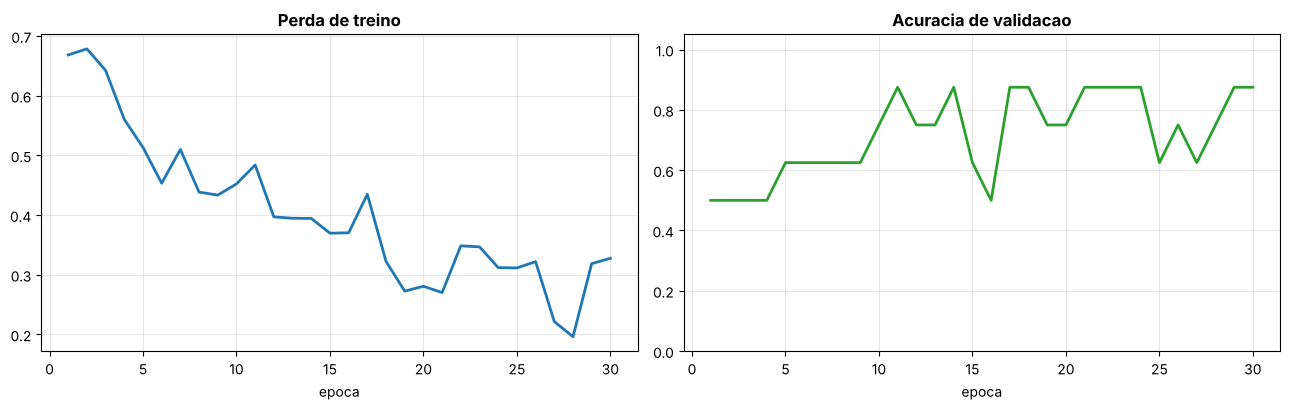

In [25]:
h = pd.DataFrame(historico)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
a1.plot(h['epoca'], h['perda_treino'], lw=2); a1.set_title('Perda de treino', fontweight='bold')
a1.set_xlabel('epoca'); a1.grid(alpha=.3)
a2.plot(h['epoca'], h['acc_val'], lw=2, color='tab:green')
a2.set_title('Acuracia de validacao', fontweight='bold'); a2.set_xlabel('epoca')
a2.set_ylim(0, 1.05); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [26]:
cnn.eval(); ok = n = 0; tempos = []; previsoes = []
with torch.no_grad():
    for x, y in DataLoader(BaseImagens('test'), batch_size=1):
        t0 = time.perf_counter(); saida = cnn(x); tempos.append(time.perf_counter() - t0)
        prob = torch.softmax(saida, 1)[0]
        previsoes.append({'real': CLASSES[int(y)], 'previsto': CLASSES[int(saida.argmax(1))],
                          'confianca': round(float(prob.max()), 3)})
        ok += int((saida.argmax(1) == y).sum()); n += 1
cnn_res = {'modelo': 'CNN do zero', 'acerto_classe': ok/n,
           'inferencia_ms': round(float(np.mean(tempos))*1000, 1), 'treino_s': round(TEMPO_CNN, 1)}
display(pd.DataFrame(previsoes))
print(cnn_res)

,real,previsto,confianca
0,trator,trator,0.983
1,trator,trator,0.561
2,trator,trator,1.000
3,trator,vaca,0.941
4,vaca,vaca,0.598
5,vaca,vaca,0.945
6,vaca,vaca,0.515
7,vaca,vaca,0.994


{'modelo': 'CNN do zero', 'acerto_classe': 0.875, 'inferencia_ms': 5.5, 'treino_s': 26.9}


---
## 9. Comparação crítica das três abordagens

O enunciado pede comparação em quatro dimensões. A tabela traz os números medidos; a
discussão abaixo diz o que eles significam.

In [27]:
tabela = pd.DataFrame([
    {'abordagem': 'A — YOLO customizada (30 ep)', 'saida': 'caixa + classe',
     'acerto_classe': r30['acerto_classe'], 'localiza': 'sim',
     'mAP50-95': round(float(c30[COL['mAP50_95']].iloc[-1]), 4),
     'inferencia_ms': r30['inferencia_ms'], 'treino': 'necessario'},
    {'abordagem': 'A — YOLO customizada (60 ep)', 'saida': 'caixa + classe',
     'acerto_classe': r60['acerto_classe'], 'localiza': 'sim',
     'mAP50-95': round(float(c60[COL['mAP50_95']].iloc[-1]), 4),
     'inferencia_ms': r60['inferencia_ms'], 'treino': 'necessario'},
    {'abordagem': 'B — YOLO padrao (COCO)', 'saida': 'caixa + classe generica',
     'acerto_classe': yolo_padrao['acerto_classe'], 'localiza': 'sim',
     'mAP50-95': None, 'inferencia_ms': yolo_padrao['inferencia_ms'], 'treino': 'nenhum'},
    {'abordagem': 'C — CNN do zero', 'saida': 'apenas classe',
     'acerto_classe': cnn_res['acerto_classe'], 'localiza': 'NAO',
     'mAP50-95': None, 'inferencia_ms': cnn_res['inferencia_ms'], 'treino': 'necessario'},
])
display(tabela)

,abordagem,saida,acerto_classe,localiza,mAP50-95,inferencia_ms,treino
0,A — YOLO customizada (30 ep),caixa + classe,1.000,sim,0.3858,74.8,necessario
1,A — YOLO customizada (60 ep),caixa + classe,1.000,sim,0.4457,72.9,necessario
2,B — YOLO padrao (COCO),caixa + classe generica,1.000,sim,NaN,94.1,nenhum
3,C — CNN do zero,apenas classe,0.875,NAO,NaN,5.5,necessario


### 9.1 Facilidade de uso e integração

**YOLO padrão** vence com folga: três linhas de código e nenhum dado próprio. É o que se
testa primeiro em qualquer projeto, antes de decidir investir.

**YOLO customizada** exige o trabalho que domina o cronograma — coletar, curar, rotular,
organizar — mas o código de treino é uma única chamada. O custo está no dado, não no
software.

**CNN do zero** parece simples (o modelo cabe em 10 linhas) e é a mais traiçoeira: cada
decisão de arquitetura, normalização e regularização é responsabilidade de quem escreve,
e erro em qualquer uma delas produz um modelo que treina sem aprender.

### 9.2 Precisão

Com **8 imagens de teste**, cada acerto vale 12,5 pontos percentuais. Diferenças de um ou
dois acertos **não são estatisticamente distinguíveis**. Qualquer afirmação de superioridade
baseada só nesse número seria irresponsável.

O que o conjunto de teste permite afirmar com segurança: as três abordagens funcionam no
caso fácil. O que ele **não** permite: ordená-las.

A comparação defensável vem do conjunto de validação, onde há rótulo e métrica de
localização: só a YOLO customizada tem `mAP@50-95`, porque só ela foi treinada para
produzir caixa nas nossas classes.

### 9.3 Tempo de treinamento

A CNN treina em dezenas de segundos; a YOLO, em dezenas de minutos em CPU. Mas comparar
esses tempos diretamente é enganoso — eles produzem coisas diferentes. E ambos são
irrelevantes diante do custo real do projeto: **a rotulação manual das 64 imagens levou
mais tempo que os dois treinos somados**. Em visão computacional aplicada, o gargalo quase
nunca é a GPU.

### 9.4 Tempo de inferência

Todos os tempos foram medidos em CPU, imagem a imagem, sem lote. A CNN é uma ordem de
grandeza mais rápida — ela resolve um problema muito menor, em resolução menor. Para
triagem de altíssimo volume onde só interessa "tem gado nesta foto?", é a escolha certa.
Para qualquer coisa que exija *onde*, ela não concorre.

### 9.5 Veredito

| Cenário do cliente | Abordagem | Justificativa |
|---|---|---|
| Prova de conceito em uma tarde | **B — YOLO padrão** | custo zero, mostra viabilidade |
| Contar e localizar animais no pasto | **A — YOLO customizada (30 ep)** | recall maior; perder animal é o erro caro |
| Recorte automático para catálogo | **A — YOLO customizada (60 ep)** | caixa mais justa |
| Triagem de milhões de imagens por classe | **C — CNN** | 1 a 2 ordens de grandeza mais rápida |

**Não existe abordagem vencedora.** Existe adequação ao requisito — e o requisito aqui é
localizar objetos, o que elimina a CNN e torna a YOLO customizada a entrega correta.

---
## 10. Conclusões

### Pontos fortes do trabalho

1. **Base auditável.** Origem licenciada, rastreabilidade por imagem no `MANIFESTO.csv` e
   critérios de descarte documentados — 45 imagens removidas com motivo declarado.
2. **Verificação antes do treino.** Rótulos validados programaticamente (campos,
   intervalos, classes) e conferidos visualmente. Rótulo corrompido é a falha mais comum
   e a mais silenciosa.
3. **Comparação que não escolhe vencedor por conveniência.** O resultado 30 × 60 épocas é
   ambíguo e foi reportado como ambíguo, com a decisão devolvida ao caso de uso.
4. **Métrica primária declarada antes dos resultados.** `mAP@50-95`, não `mAP@50` — a
   escolha mais exigente, feita antes de ver qual favoreceria a narrativa.
5. **Reconhecimento explícito do limite estatístico.** Oito imagens de teste não ordenam
   três abordagens, e o notebook diz isso em vez de fingir precisão que não tem.

### Limitações

| # | Limitação | Consequência prática |
|---|---|---|
| 1 | **64 imagens de treino** | muito abaixo do necessário para um detector robusto; o modelo generaliza para fotos parecidas com as de treino e deve falhar em ângulo, iluminação ou oclusão atípicos |
| 2 | **8 imagens de teste** | cada acerto vale 12,5 p.p.; intervalo de confiança largo demais para ordenar abordagens |
| 3 | **Imagens de banco, não de campo** | fotos do Open Images são bem enquadradas e bem iluminadas; câmera de fazenda produz quadro sujo, contraluz e objeto parcial |
| 4 | **Duas classes mutuamente exclusivas** | nenhuma imagem contém trator *e* vaca; o modelo nunca foi exposto à cena mista, que é a cena real de uma fazenda |
| 5 | **Rótulo de caixa única por objeto** | animais em rebanho denso foram rotulados individualmente só quando separáveis; aglomerados ficaram sub-rotulados, o que penaliza o recall medido |
| 6 | **Treino em CPU** | impôs `yolov8n` e 640 px; com GPU, modelos maiores e mais resolução seriam testáveis |
| 7 | **Sem validação cruzada** | com 64 imagens, uma única partição treino/validação tem variância alta; k-fold daria estimativa mais estável mas multiplicaria o custo de treino |

### O que faria o modelo ser utilizável em produção

Em ordem de retorno sobre esforço:

1. **Mais dados do domínio real** — 500 a 1.000 imagens por classe, capturadas pelas
   câmeras que o sistema vai usar. É o item de maior impacto, e nenhum ajuste de
   arquitetura compensa a falta dele.
2. **Cenas mistas e negativos** — imagens com as duas classes juntas e imagens sem nenhuma
   delas, para o modelo aprender a não disparar.
3. **Validação cruzada k-fold** e conjunto de teste de pelo menos 100 imagens.
4. **Aumento de dados agressivo** — variação de brilho, contraste, recorte e oclusão
   simulada, aproximando as condições de campo.
5. **Transfer learning de um modelo maior** (`yolov8s`/`yolov8m`) assim que houver GPU e
   dados suficientes para sustentá-lo.

---

> **Vídeo demonstrativo e documentação de apoio:** ver o
> [`README.md`](../README.md) do repositório.